In [16]:
# !pip install geopandas pandas matplotlib mapclassify requests
import pandas as pd
from pathlib import Path
import numpy as np
import geopandas as gpd

import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, TwoSlopeNorm, Normalize
from matplotlib.cm import ScalarMappable

OUT = Path("../outputs")
OUT.mkdir(exist_ok=True)         # crea la carpeta de salida si no existe

In [17]:
url = "https://datahub.io/core/eu-emissions-trading-system/r/eu-ets.csv"
df = pd.read_csv(url)
print(df.columns.tolist())
df.head()

['country_code', 'main_activity_code', 'main_activity_name', 'citl_information', 'year', 'value']


,country_code,main_activity_code,main_activity_name,citl_information,year,value
0,AT,10,10 Aviation,1. Total allocated allowances (EUA or EUAA),2005,0.0
1,AT,20,20 Combustion of fuels,1. Total allocated allowances (EUA or EUAA),2005,14362552.0
2,AT,20-99,20-99 All stationary installations,1. Total allocated allowances (EUA or EUAA),2005,32412654.0
3,AT,21,21 Refining of mineral oil,1. Total allocated allowances (EUA or EUAA),2005,2720740.0
4,AT,21-99,21-99 All industrial installations (excl. comb...,1. Total allocated allowances (EUA or EUAA),2005,18050102.0


In [18]:
print(df["citl_information"].unique())

<ArrowStringArray>
[                                 '1. Total allocated allowances (EUA or EUAA)',
                                              '1.1 Freely allocated allowances',
                     '1.1.1 Free allocation to existing entities (Art. 10a(1))',
            '1.1.2 Free allocation from the new entrants reserve (Art. 10a(7))',
                 '1.1.4 Swiss Free Allocated allowances for aircraft operators',
        '1.2 Correction to freely allocated allowances (not reflected in EUTL)',
                            '1.3 Allowances auctioned or sold (EUAs and EUAAs)',
                                                        '2. Verified emissions',
                                                 '2.1 EU-ETS Verified Emission',
        '2.1b EU-ETS Verified Emissions (expected, gap-filled for latest year)',
                          '2.2 Swiss Verified Emissions for aircraft operators',
        '3. Estimate to reflect current ETS scope for allowances and emissions',
         

In [19]:
print(df["main_activity_code"].unique())

<ArrowStringArray>
[   '10',    '20', '20-99',    '21', '21-99',    '22',    '24',    '29',
    '30',    '31',    '32',    '35',    '36',    '42',    '99',    '38',
    '25',    '27',    '28',    '34',    '41',    '43',    '26',    '33',
    '37',    '50',    '44',    '23',    '39',    '40',    '45']
Length: 31, dtype: str


In [20]:
print(df["year"].unique())

<ArrowStringArray>
[                            '2005',                             '2006',
                             '2007',                             '2008',
                             '2009',                             '2010',
                             '2011',                             '2012',
                             '2013',                             '2014',
                             '2015',                             '2016',
                             '2017',                             '2018',
                             '2019',                             '2020',
                             '2021',                             '2022',
                             '2023',                             '2024',
                             '2025', 'Total 1st trading period (05-07)',
 'Total 2nd trading period (08-12)', 'Total 3rd trading period (13-20)',
 'Total 4th trading period (21-30)']
Length: 25, dtype: str


In [21]:
print(df["country_code"].unique())

<ArrowStringArray>
[                'AT',                 'BE',                 'BG',
                 'CY',                 'CZ',                 'DE',
                 'DK',                 'EE',                 'ES',
                 'FI',                 'FR',                 'GB',
                 'GR',                 'HR',                 'HU',
                 'IE',                 'IS',                 'IT',
    'Innovation fund',                 'LI',                 'LT',
                 'LU',                 'LV',                 'MT',
 'Modernisation Fund',   'NER 300 auctions',                 'NL',
                 'NO',                 'PL',                 'PT',
                 'RO',                'RRF',                 'SE',
                 'SI',                 'SK',                 'XI']
Length: 36, dtype: str


In [22]:
YEAR = "2023"   # ajusta según lo que veas en df["year"].unique()

ver = df[
    df["citl_information"].str.contains("Verified emissions", case=False, na=False)
    & (df["year"].astype(str) == YEAR)
]

# Instalaciones fijas (agregado oficial, sin doble conteo)
stationary = (
    ver[ver["main_activity_code"].astype(str) == "20-99"]
    .groupby("country_code", as_index=False)["value"].sum()
    .rename(columns={"value": "stationary"})
)

# Aviación (opcional)
aviation = (
    ver[ver["main_activity_code"].astype(str) == "10"]
    .groupby("country_code", as_index=False)["value"].sum()
    .rename(columns={"value": "aviation"})
)

emis = stationary.merge(aviation, on="country_code", how="left").fillna(0)
emis["total"] = emis["stationary"] + emis["aviation"]
emis["value_mt"] = emis["total"] / 1e6   # millones de t CO2e
emis.sort_values("value_mt", ascending=False).head(10)

,country_code,stationary,aviation,total,value_mt
5,DE,289340809.0,7795855.0,297136664.0,297.136664
23,PL,153018903.0,976058.0,153994961.0,153.994961
16,IT,114784026.0,2562231.0,117346257.0,117.346257
8,ES,81133557.0,8049971.0,89183528.0,89.183528
10,FR,70652409.0,3209197.0,73861606.0,73.861606
21,NL,58888869.0,2726333.0,61615202.0,61.615202
4,CZ,46672102.0,263938.0,46936040.0,46.936040
1,BE,35402662.0,1072000.0,36474662.0,36.474662
0,AT,24413340.0,3313347.0,27726687.0,27.726687
11,GR,25466136.0,1368235.0,26834371.0,26.834371


In [23]:
gisco = "https://gisco-services.ec.europa.eu/distribution/v2/countries/geojson/CNTR_RG_20M_2020_4326.geojson"
world = gpd.read_file(gisco)

# GISCO usa EL para Grecia; el CSV probablemente usa GR
emis["country_code"] = emis["country_code"].replace({"GR": "EL"})

In [24]:
europe = world.merge(emis, left_on="CNTR_ID", right_on="country_code", how="left").to_crs(3035)

# Países del CSV que no encontraron polígono
print(set(emis["country_code"]) - set(world["CNTR_ID"]))

set()


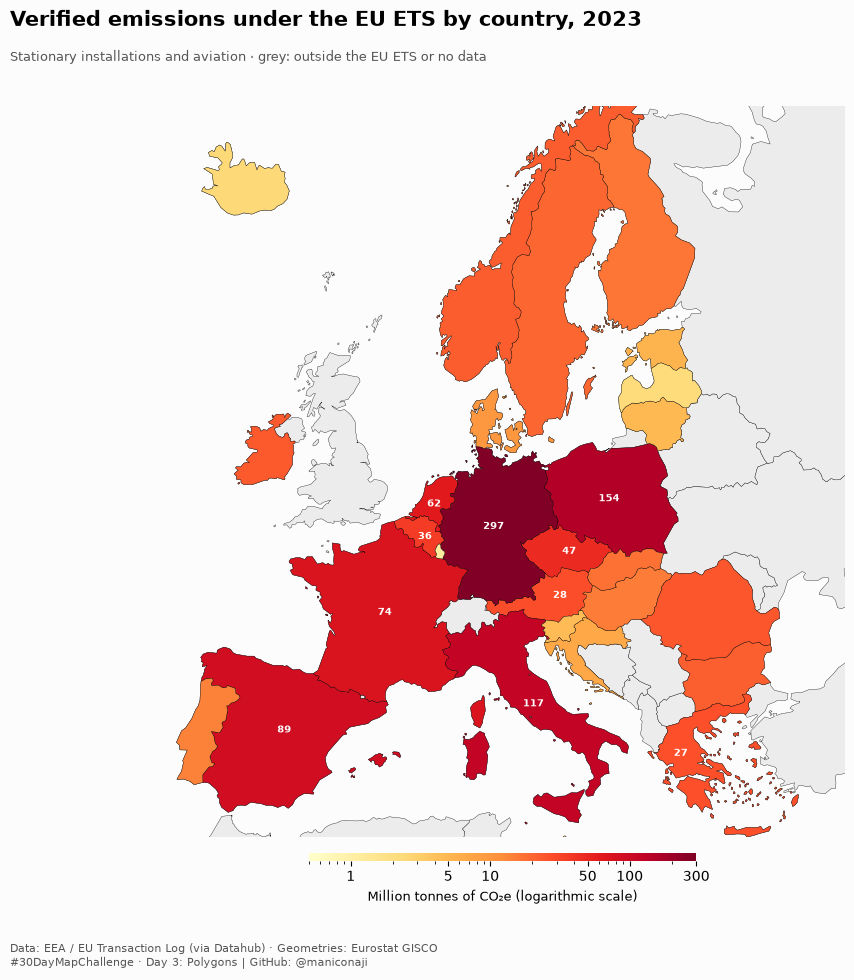

In [25]:
fig, ax = plt.subplots(figsize=(10, 10), facecolor="#FCFCFC")

norm = LogNorm(vmin=0.5, vmax=300)
cmap = "YlOrRd"

# Background: countries without data
europe.plot(ax=ax, color="#ececec", edgecolor="k", linewidth=0.25)

# Countries with data
data = europe.dropna(subset=["value_mt"])
data.plot(
    column="value_mt", 
    ax=ax, 
    cmap=cmap, 
    norm=norm,
    edgecolor="k", 
    linewidth=0.25)

# Labels: top 10 emitters
top = data.nlargest(10, "value_mt").copy()
top["pt"] = top.geometry.representative_point()
for _, r in top.iterrows():
    ax.annotate(
        f"{r['value_mt']:.0f}", xy=(r["pt"].x, r["pt"].y),
        ha="center", 
        va="center", 
        fontsize=7.5,
        fontweight="bold", 
        color="white")

# Compact colorbar
sm = ScalarMappable(norm=norm, cmap=cmap)
cbar = fig.colorbar(
    sm, 
    ax=ax, 
    orientation="horizontal",
    fraction=0.03, 
    pad=0.02, 
    shrink=0.5, 
    aspect=50)
cbar.set_ticks([1, 5, 10, 50, 100, 300])
cbar.set_ticklabels(["1", "5", "10", "50", "100", "300"])
cbar.set_label("Million tonnes of CO₂e (logarithmic scale)", fontsize=9)
cbar.outline.set_visible(False)

# Map extent
ax.set_xlim(2.55e6, 6.2e6)
ax.set_ylim(1.45e6, 5.35e6)
ax.set_axis_off()

# Title and subtitle, aligned to the same anchor
fig.text(
    0.02, 0.96, 
    "Verified emissions under the EU ETS by country, 2023",
    ha="left", 
    fontsize=15, 
    fontweight="bold")
fig.text(
    0.02, 0.925, 
    "Stationary installations and aviation · grey: outside the EU ETS or no data",
    ha="left", 
    fontsize=9.5, 
    color="#555")

fig.text(
    0.02, 0.02,
    "Data: EEA / EU Transaction Log (via Datahub) · Geometries: Eurostat GISCO\n"
    "#30DayMapChallenge · Day 3: Polygons | GitHub: @maniconaji",
    fontsize=8, 
    color="#555")

plt.savefig(OUT / "day03_polygons_en.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

In [26]:
CAT_VERIFIED = "2. Verified emissions"
CAT_FILLED = "2.1b EU-ETS Verified Emissions (expected, gap-filled for latest year)"

def stationary_emissions(year, category=CAT_VERIFIED):
    sel = df[
        (df["citl_information"] == category)
        & (df["year"].astype(str) == year)
        & (df["main_activity_code"].astype(str) == "20-99")
    ]
    return sel.groupby("country_code")["value"].sum()

# Comprobación: Alemania 2025 con cada categoría (Mt)
for cat in (CAT_VERIFIED, CAT_FILLED):
    print(cat[:30], round(stationary_emissions("2025", cat).get("DE", float("nan")) / 1e6, 1))

BASE_YEAR = "2005"
END_YEAR = "2025"
END_CAT = CAT_FILLED if END_YEAR == "2025" else CAT_VERIFIED   # gap-filled solo para el último año

base = stationary_emissions(BASE_YEAR)
end = stationary_emissions(END_YEAR, END_CAT)

change = pd.DataFrame({"base": base, "end": end}).dropna()
change = change[change["base"] > 0]
change["pct"] = (change["end"] / change["base"] - 1) * 100
change = change.reset_index()
change["country_code"] = change["country_code"].replace({"GR": "EL"})

print(change.sort_values("pct")[["country_code", "pct"]].round(1).to_string(index=False))

europe_chg = world.merge(change, left_on="CNTR_ID", right_on="country_code", how="left").to_crs(3035)

2. Verified emissions 263.6
2.1b EU-ETS Verified Emissions 265.3
country_code   pct
          DK -70.2
          PT -68.7
          EE -67.3
          FI -64.1
          EL -63.7
          MT -63.5
          XI -63.3
          LU -62.6
          SI -57.9
          ES -57.3
          HU -57.1
          IT -55.1
          FR -53.4
          IE -52.5
          CZ -51.4
          DE -44.1
          SK -42.0
          LV -41.8
          BE -34.8
          LT -30.2
          PL -28.2
          AT -23.3
          NL -23.0
          SE -16.5
          CY -14.7


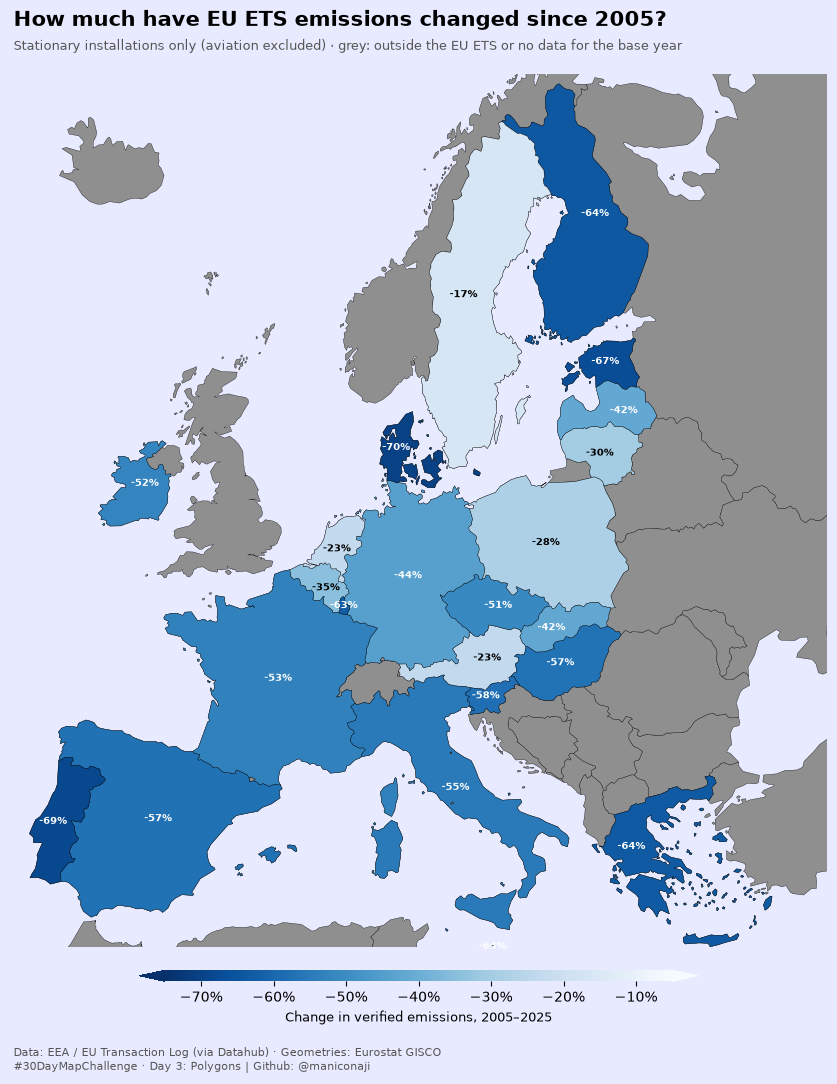

In [28]:
# ---- Map ----
fig, ax = plt.subplots(figsize=(12, 12), facecolor="#E8EBFF")

norm = Normalize(vmin=-75, vmax=-5)   # ajusta según los datos que veas
cmap = "Blues_r"                                      # azul = reducción, rojo = aumento

# Background: countries without data
europe_chg.plot(ax=ax, color="#8F8F8F", edgecolor="k", linewidth=0.25)
data = europe_chg.dropna(subset=["pct"])
data.plot(
    column="pct", 
    ax=ax, 
    cmap=cmap, 
    norm=norm,
    edgecolor="k", 
    linewidth=0.25)

# Labels for the 12 largest emitters in the end year
top = data.copy() # data.nlargest(12, "end")
top["pt"] = top.geometry.representative_point()
for _, r in top.iterrows():
    if r['pct'] < -40:
        ax.annotate(
            f"{r['pct']:+.0f}%", xy=(r["pt"].x, r["pt"].y),
            ha="center", va="center", fontsize=7,
            fontweight="bold", color="#FFFFFF")
    else:
        ax.annotate(
            f"{r['pct']:+.0f}%", xy=(r["pt"].x, r["pt"].y),
            ha="center", va="center", fontsize=7,
            fontweight="bold", color="#000000")

sm = ScalarMappable(norm=norm, cmap=cmap)
cbar = fig.colorbar(
    sm, ax=ax, orientation="horizontal",
    fraction=0.03, pad=0.025, shrink=0.60, aspect=50, extend="both")
ticks = [-70, -60, -50, -40, -30, -20, -10]
cbar.set_ticks(ticks)
cbar.set_ticklabels([f"{t}%".replace("-", "−") for t in ticks])
cbar.set_label(f"Change in verified emissions, {BASE_YEAR}–{END_YEAR}", fontsize=9)
cbar.outline.set_visible(False)

ax.set_xlim(2.55e6, 6.2e6)
ax.set_ylim(1.45e6, 5.35e6)
ax.set_axis_off()

fig.text(
    0.175, 0.92,
    f"How much have EU ETS emissions changed since {BASE_YEAR}?", 
    ha="left", fontsize=15, fontweight="bold")
fig.text(
    0.175, 0.90,
    "Stationary installations only (aviation excluded) · grey: outside the EU ETS or no data for the base year",
    ha="left", fontsize=9.5, color="#555")
fig.text(
    0.175, 0.05,
    "Data: EEA / EU Transaction Log (via Datahub) · Geometries: Eurostat GISCO\n"
    "#30DayMapChallenge · Day 3: Polygons | Github: @maniconaji",
    fontsize=8, color="#555")

plt.savefig(OUT / "day03_polygons_change.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()